# Phase 5 — Two-slot allocator: a linear program

**Purpose.** Phase 4 produced a scored list of candidates. You have two
slots, limited cash and several rules. This notebook picks the positions
and their sizes with an optimiser, and then asks the optimiser which rule
is holding the result back.

**Mission.**

1. Which candidates fill the two slots, and with how many shares?
2. Which limit binds: cash, the gap budget, the slot count, the 1R cap?
3. What is each rule worth? What would relaxing it buy?

**The linear algebra.** A linear program is three arrays:

> maximise `cᵀv` subject to `A v ≤ b`

`v` is the vector of decisions, `c` the value of one unit of each decision,
each row of `A` is one limited resource, and `b` holds the limits.

**It is the same structure as a refinery planning LP.**

| Refinery LP | This allocator |
|---|---|
| activity levels (crude runs, blends) | shares of each candidate |
| margin per unit of activity | setup score per R of risk |
| unit capacities | cash, gap budget, slot count |
| product specifications | at most one stock per theme, 1R cap per slot |
| shadow price (marginal value) of a capacity | what one more unit of a limit is worth |
| whole batches or on/off units (integer) | whole shares, pick or not (integer) |

**Read this first.** The objective uses the Phase 4 setup score as the
value of a candidate. That score has **not** been tested as a predictor of
returns. The allocator therefore applies your rules consistently to the
scanner's ranking; it does not maximise expected profit. Study tool, not
advice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import lab_style as ls
import allocator as al
import scanner as sc

ls.use_lab_style()
pd.set_option("display.width", 200)

In [2]:
# ============================================================
# KEY IN HERE
# ============================================================
EQUITY         = 2000    # account in $
RISK_PCT       = 0.01    # 1R as a fraction of equity
STOP_ADR       = 0.5     # stop distance, in ADR (0.5 = half a day's range)
MAX_SLOTS      = 2       # open positions allowed
GAP_BUDGET_PCT = 0.03    # largest loss accepted if every pick gaps one ADR
MAX_EXT_ADR    = 1.0     # skip candidates further than this above the 10-day MA

ONE_R = EQUITY * RISK_PCT
GAP_BUDGET_R = GAP_BUDGET_PCT / RISK_PCT
print(f"1R = ${ONE_R:,.0f}   slot cash = ${EQUITY / MAX_SLOTS:,.0f}   "
      f"gap budget = {GAP_BUDGET_R:.1f}R (${EQUITY * GAP_BUDGET_PCT:,.0f})")

1R = $20   slot cash = $1,000   gap budget = 3.0R ($60)


## Step 1 — Candidates and the numbers the program needs

| Column | Meaning |
|---|---|
| `stop_pct` | stop distance as a fraction of price: `STOP_ADR × ADR` |
| `share_R` | risk of **one share**, in R: `price × stop_pct ÷ 1R` |
| `cost_per_R` | dollars of stock that carry 1R of risk: `1R ÷ stop_pct` |
| `gap_R` | loss in R, per 1R risked, if the stock opens one ADR lower: `1 ÷ STOP_ADR` |
| `max_R` | most risk the slot may carry: 1R, or less if the slot's cash runs out |
| `value` | setup score ÷ 100 |

In [3]:
all_cands = pd.read_csv("candidates.csv", index_col=0)
cands = all_cands[all_cands["ext_adr"] <= MAX_EXT_ADR]
dropped = sorted(set(all_cands.index) - set(cands.index))
print(f"Candidates from Phase 4: {len(all_cands)}   "
      f"dropped as extended: {', '.join(dropped) or 'none'}")

prices = sc.load_prices()
regime = sc.market_regime(prices["Close"], "QQQ")
print(f"Regime gate: {'OPEN' if regime['gate_open'] else 'CLOSED'}\n")

prep = al.prepare(cands, EQUITY, RISK_PCT, STOP_ADR, MAX_SLOTS)
print(prep[["price", "adr_pct", "stop_pct", "share_R", "cost_per_R", "gap_R",
            "max_R", "value", "theme"]].round(3).to_string())

Candidates from Phase 4: 10   dropped as extended: APP, DUOL, LUNR, TTD
Regime gate: CLOSED

       price  adr_pct  stop_pct  share_R  cost_per_R  gap_R  max_R  value theme
MRNA  223.37    10.20     0.051    0.570     392.157    2.0    1.0  0.842  solo
CELH   32.42     4.74     0.024    0.038     843.882    2.0    1.0  0.770  solo
CVNA   72.37     5.12     0.026    0.093     781.250    2.0    1.0  0.767  solo
ELF   117.98     4.63     0.023    0.137     863.931    2.0    1.0  0.688  solo
RUN     8.63     7.48     0.037    0.016     534.759    2.0    1.0  0.636  solo
RIOT   17.52     9.35     0.047    0.041     427.807    2.0    1.0  0.614    T5


Look at `share_R`. It says how coarse the sizing is. A value of 0.57 means
one share is already 0.57R, so the position can only be 0.57R or 1.14R,
never 1R. On a small account, expensive stocks cannot be sized finely.

## Step 2 — The program as three arrays

The decision vector `v` holds, for each candidate, the number of shares
`s` and a pick flag `x` (1 or 0). Each row of `A` is one rule.

In [4]:
problem = al.build_problem(prep, EQUITY, MAX_SLOTS, GAP_BUDGET_R)
n = problem["n"]
columns = [f"s_{t}" for t in problem["tickers"]] + [f"x_{t}" for t in problem["tickers"]]

print(f"decision vector v: {2 * n} entries ({n} share counts, {n} pick flags)")
print(f"objective vector c: shape {problem['c'].shape}")
print(f"constraint matrix A: shape {problem['A'].shape}   limits b: shape {problem['b'].shape}\n")

A_table = pd.DataFrame(problem["A"], index=problem["rows"], columns=columns)
A_table["≤ b"] = problem["b"]
print(A_table.round(3).to_string())

decision vector v: 12 entries (6 share counts, 6 pick flags)
objective vector c: shape (12,)
constraint matrix A: shape (9, 12)   limits b: shape (9,)

            s_MRNA  s_CELH  s_CVNA    s_ELF  s_RUN  s_RIOT  x_MRNA  x_CELH  x_CVNA  x_ELF  x_RUN  x_RIOT     ≤ b
slots        0.000   0.000   0.000    0.000  0.000   0.000     1.0     1.0     1.0    1.0    1.0     1.0     2.0
cash       223.370  32.420  72.370  117.980  8.630  17.520     0.0     0.0     0.0    0.0    0.0     0.0  2000.0
gap          1.139   0.077   0.185    0.273  0.032   0.082     0.0     0.0     0.0    0.0    0.0     0.0     3.0
link MRNA    0.570   0.000   0.000    0.000  0.000   0.000    -1.0     0.0     0.0    0.0    0.0     0.0     0.0
link CELH    0.000   0.038   0.000    0.000  0.000   0.000     0.0    -1.0     0.0    0.0    0.0     0.0     0.0
link CVNA    0.000   0.000   0.093    0.000  0.000   0.000     0.0     0.0    -1.0    0.0    0.0     0.0     0.0
link ELF     0.000   0.000   0.000    0.137  0.000   0.00

Reading the rows:

- **slots:** the pick flags add up to at most 2.
- **cash:** shares × price add up to at most the account.
- **gap:** shares × (loss per share on a one-ADR gap, in R) add up to at
  most the gap budget.
- **link:** `share_R × s − max_R × x ≤ 0`. If the stock is not picked
  (`x = 0`) its shares must be 0. If picked, its risk is at most `max_R`.

## Step 3 — Solve

In [5]:
shares, objective = al.solve(problem)
orders = al.to_orders(prep, shares)

print(orders.round(2).to_string())
print(f"\nObjective (score-weighted risk): {objective:.3f}")
print(f"Cash used     : ${orders['cost'].sum():,.0f} of ${EQUITY:,}  "
      f"({orders['cost'].sum() / EQUITY:.0%})")
print(f"Risk deployed : {orders['risk_R'].sum():.2f}R of {MAX_SLOTS}R  "
      f"(${orders['risk_R'].sum() * ONE_R:,.0f})")
print(f"Gap loss      : {orders['gap_loss_R'].sum():.2f}R of {GAP_BUDGET_R:.1f}R budget")

       price  stop_price  stop_pct  shares    cost  risk_R  max_R  gap_loss_R  score theme
MRNA  223.37      211.98      0.05       1  223.37    0.57    1.0        1.14   84.2  solo
CVNA   72.37       70.52      0.03      10  723.70    0.93    1.0        1.85   76.7  solo

Objective (score-weighted risk): 1.190
Cash used     : $947 of $2,000  (47%)
Risk deployed : 1.50R of 2R  ($30)
Gap loss      : 2.99R of 3.0R budget


## Step 4 — The picture: feasible region and optimum

With the two picks fixed, the problem has two unknowns: the risk in each
stock. That can be drawn. Each rule is a straight line. The shaded area is
every combination that obeys all the rules (the **feasible region**). The
best point of a linear program always sits on a corner of that region.

The dots are the combinations reachable with whole shares.

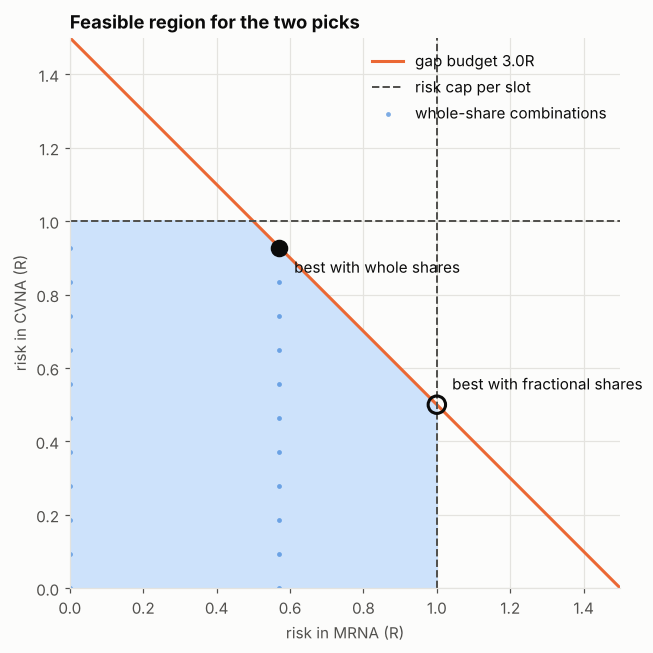

The cash limit lies outside the chart: cash is far from binding here.
Fractional shares: MRNA 1.00R, CVNA 0.50R, objective 1.226
Whole shares     : MRNA 0.57R, CVNA 0.93R, objective 1.190


In [6]:
picks = list(orders.index)
a, b_ = picks[0], picks[1]
pa, pb = prep.loc[a], prep.loc[b_]
price_table, lp_y = al.shadow_prices(prep, picks, EQUITY, GAP_BUDGET_R)

grid = np.linspace(0, 1.5, 400)
ya, yb = np.meshgrid(grid, grid)
feasible = ((ya <= pa["max_R"]) & (yb <= pb["max_R"])
            & (pa["cost_per_R"] * ya + pb["cost_per_R"] * yb <= EQUITY)
            & (pa["gap_R"] * ya + pb["gap_R"] * yb <= GAP_BUDGET_R))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.contourf(ya, yb, feasible.astype(float), levels=[0.5, 1.5], colors=[ls.BLUE_BAND_OUTER])
line = np.linspace(0, 1.5, 50)
ax.plot(line, (GAP_BUDGET_R - pa["gap_R"] * line) / pb["gap_R"], color=ls.ORANGE,
        label=f"gap budget {GAP_BUDGET_R:.1f}R")
cash_line = (EQUITY - pa["cost_per_R"] * line) / pb["cost_per_R"]
cash_visible = cash_line.min() < 1.5
if cash_visible:
    ax.plot(line, cash_line, color=ls.AQUA, label=f"cash ${EQUITY:,}")
ax.axvline(pa["max_R"], color=ls.TEXT_SOFT, ls="--", lw=1.3, label="risk cap per slot")
ax.axhline(pb["max_R"], color=ls.TEXT_SOFT, ls="--", lw=1.3)

sa = np.arange(0, int(1.5 / pa["share_R"]) + 1) * pa["share_R"]
sb = np.arange(0, int(1.5 / pb["share_R"]) + 1) * pb["share_R"]
ga, gb = np.meshgrid(sa, sb)
ok = ((ga <= pa["max_R"] + 1e-9) & (gb <= pb["max_R"] + 1e-9)
      & (pa["cost_per_R"] * ga + pb["cost_per_R"] * gb <= EQUITY + 1e-9)
      & (pa["gap_R"] * ga + pb["gap_R"] * gb <= GAP_BUDGET_R + 1e-9))
ax.scatter(ga[ok], gb[ok], s=10, color=ls.BLUE, alpha=0.6, linewidths=0,
           label="whole-share combinations")

ax.scatter([lp_y[0]], [lp_y[1]], s=130, facecolor="none", edgecolor=ls.TEXT,
           linewidth=2, zorder=5)
ax.annotate("best with fractional shares", (lp_y[0], lp_y[1]),
            textcoords="offset points", xytext=(10, 10), color=ls.TEXT)
ax.scatter([orders.loc[a, "risk_R"]], [orders.loc[b_, "risk_R"]], s=110,
           color=ls.TEXT, zorder=6)
ax.annotate("best with whole shares", (orders.loc[a, "risk_R"], orders.loc[b_, "risk_R"]),
            textcoords="offset points", xytext=(10, -16), color=ls.TEXT)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_aspect("equal")
ax.set_xlabel(f"risk in {a} (R)"); ax.set_ylabel(f"risk in {b_} (R)")
ax.set_title("Feasible region for the two picks")
ax.legend(loc="upper right")
plt.show()

if not cash_visible:
    print("The cash limit lies outside the chart: cash is far from binding here.")
print(f"Fractional shares: {a} {lp_y[0]:.2f}R, {b_} {lp_y[1]:.2f}R, "
      f"objective {prep.loc[picks, 'value'].to_numpy() @ lp_y:.3f}")
print(f"Whole shares     : {a} {orders.loc[a, 'risk_R']:.2f}R, "
      f"{b_} {orders.loc[b_, 'risk_R']:.2f}R, objective {objective:.3f}")

## Step 5 — Shadow prices: which limit is worth relaxing?

The **shadow price** of a limit is how much the objective would rise if the
limit were relaxed by one unit. A limit with spare room has a shadow price
of zero: more of it is worth nothing. This is the same reading as the
marginal value of a unit capacity in a refinery LP.

Shadow prices exist for the version with fractional shares, with the two
picks held fixed.

                   limit      used  shadow price    unit
cash              2000.0  782.7819        0.0000  per $1
gap budget           3.0    3.0000        0.3835  per 1R
risk cap of MRNA     1.0    1.0000        0.0750  per 1R
risk cap of CVNA     1.0    0.5000        0.0000  per 1R


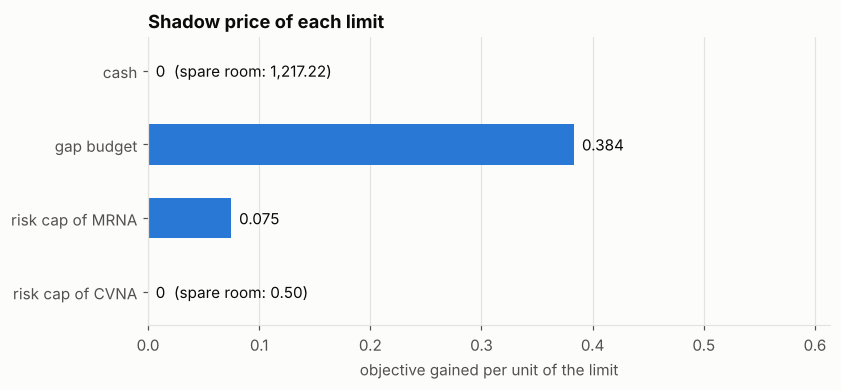

Binding limits: gap budget, risk cap of MRNA


In [7]:
print(price_table.round(4).to_string())
binding = price_table[price_table["shadow price"] > 1e-9]

fig, ax = plt.subplots(figsize=(8, 0.5 * len(price_table) + 1.4))
names = list(price_table.index)[::-1]
ax.barh(names, price_table.loc[names, "shadow price"], color=ls.BLUE, height=0.55)
for y, name in enumerate(names):
    v = price_table.loc[name, "shadow price"]
    room = price_table.loc[name, "limit"] - price_table.loc[name, "used"]
    note = f"{v:.3f}" if v > 1e-9 else f"0  (spare room: {room:,.2f})"
    ax.annotate(note, (v, y), textcoords="offset points", xytext=(5, -4), color=ls.TEXT)
ax.set_xlim(0, max(price_table["shadow price"].max() * 1.6, 0.1))
ax.grid(axis="y", visible=False)
ax.set_xlabel("objective gained per unit of the limit")
ax.set_title("Shadow price of each limit")
plt.show()

print("Binding limits:", ", ".join(binding.index) if len(binding) else "none")

## Step 6 — What each rule costs

Shadow prices are for small changes. For a whole rule, solve again with
that rule removed and compare. The gain is what the rule costs you in
objective. That cost buys safety, so a cost is not a reason to drop a rule.

                      objective               picks risk R gap loss R cash %
Your rules                 1.19         MRNA + CVNA   1.50       2.99  47.35
No gap budget              1.48         CELH + CVNA   1.93       3.85  78.33
A third slot               1.19  MRNA + CELH + CVNA   1.49       2.99  48.71
No theme rule              1.19         MRNA + CVNA   1.50       2.99  47.35
Allow extended stocks      1.19         MRNA + CVNA   1.50       2.99  47.35


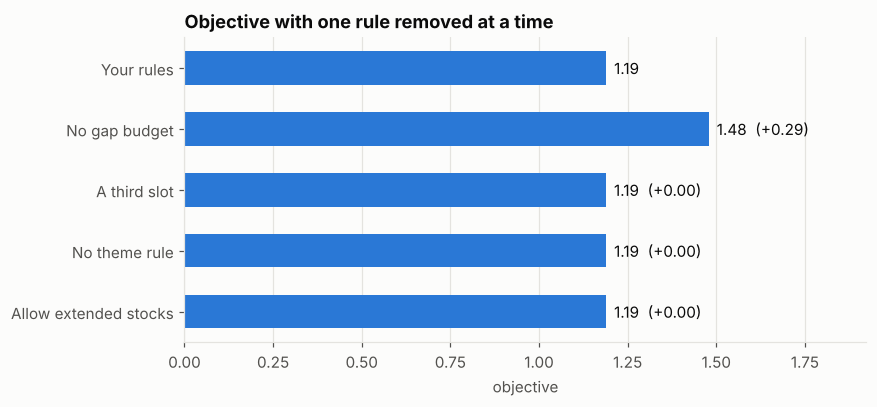

In [8]:
base = dict(equity=EQUITY, risk_pct=RISK_PCT, stop_adr=STOP_ADR,
            max_slots=MAX_SLOTS, gap_budget_R=GAP_BUDGET_R)
variants = {
    "Your rules": (cands, {}),
    "No gap budget": (cands, {"gap_budget_R": 1e6}),
    "A third slot": (cands, {"max_slots": 3}),
    "No theme rule": (cands, {"use_themes": False}),
    "Allow extended stocks": (all_cands, {}),
}
rule_rows = {}
for name, (table, change) in variants.items():
    o, value, _ = al.allocate(table, **{**base, **change})
    rule_rows[name] = {"objective": value, "picks": " + ".join(o.index),
                       "risk R": o["risk_R"].sum(), "gap loss R": o["gap_loss_R"].sum(),
                       "cash %": 100 * o["cost"].sum() / EQUITY}
rules = pd.DataFrame(rule_rows).T
print(rules.to_string(float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(8, 3.6))
order = list(rules.index)[::-1]
gain = (rules.loc[order, "objective"] - rules.loc["Your rules", "objective"]).astype(float).round(2)
ax.barh(order, rules.loc[order, "objective"].astype(float), color=ls.BLUE, height=0.55)
for y, name in enumerate(order):
    v = float(rules.loc[name, "objective"])
    text = f"{v:.2f}" if name == "Your rules" else f"{v:.2f}  ({gain[name] + 0.0:+.2f})"
    ax.annotate(text, (v, y), textcoords="offset points", xytext=(5, -4), color=ls.TEXT)
ax.set_xlim(0, float(rules["objective"].max()) * 1.3); ax.grid(axis="y", visible=False)
ax.set_xlabel("objective"); ax.set_title("Objective with one rule removed at a time")
plt.show()

## Step 7 — Stop width and risk setting

A tighter stop buys more shares for the same risk, so it uses more cash and
loses more R on a gap. A higher risk setting shrinks the gap budget when
counted in R. The table shows where each combination ends up.

 risk %  stop (ADR)       picks  risk R  risk $  cash %  gap loss $
   0.50        1.00  CELH + RUN    1.89   18.90   16.20       18.90
   0.50        0.50 CELH + CVNA    1.93   19.25   39.17       38.50
   0.50        0.30 CELH + CVNA    1.77   17.65   59.75       58.84
   1.00        1.00 CELH + CVNA    1.93   38.50   39.17       38.50
   1.00        0.50 MRNA + CVNA    1.50   29.92   47.35       59.84
   1.00        0.30 MRNA + CELH    0.89   17.82   36.93       59.40
   2.50        1.00 MRNA + CELH    1.19   59.40   36.93       59.40
   2.50        0.50 MRNA + CELH    0.59   29.70   36.93       59.40
   2.50        0.30 MRNA + CELH    0.36   17.82   36.93       59.40


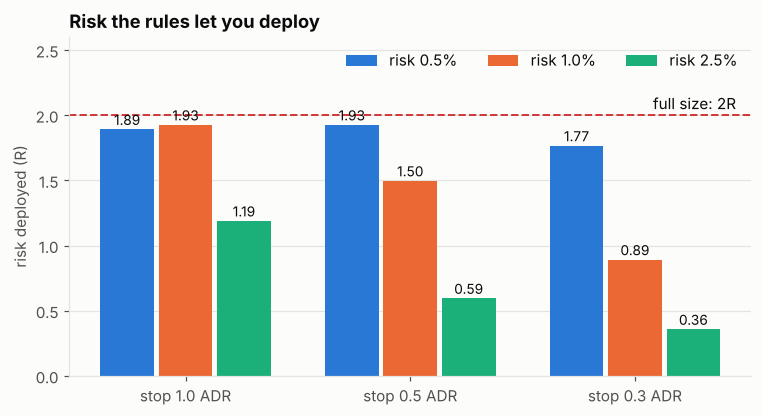

In [9]:
grid_rows = []
for risk in [0.005, 0.01, 0.025]:
    for stop in [1.0, 0.5, 0.3]:
        o, value, _ = al.allocate(cands, EQUITY, risk, stop, MAX_SLOTS,
                                  GAP_BUDGET_PCT / risk)
        grid_rows.append({"risk %": 100 * risk, "stop (ADR)": stop,
                          "picks": " + ".join(o.index),
                          "risk R": o["risk_R"].sum(),
                          "risk $": o["risk_R"].sum() * EQUITY * risk,
                          "cash %": 100 * o["cost"].sum() / EQUITY,
                          "gap loss $": o["gap_loss_R"].sum() * EQUITY * risk})
scen = pd.DataFrame(grid_rows)
print(scen.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(8, 4))
width = 0.26
stops = [1.0, 0.5, 0.3]
for k, (risk, color) in enumerate(zip([0.5, 1.0, 2.5], [ls.BLUE, ls.ORANGE, ls.AQUA])):
    part = scen[scen["risk %"] == risk].set_index("stop (ADR)").loc[stops]
    xpos = np.arange(len(stops)) + (k - 1) * width
    ax.bar(xpos, part["risk R"], width=width * 0.92, color=color, label=f"risk {risk}%")
    for xp, v in zip(xpos, part["risk R"]):
        ax.annotate(f"{v:.2f}", (xp, v), ha="center", textcoords="offset points",
                    xytext=(0, 3), color=ls.TEXT, fontsize=9)
ax.axhline(MAX_SLOTS, color=ls.CRITICAL, ls="--", lw=1.3)
ax.annotate(f"full size: {MAX_SLOTS}R", (len(stops) - 0.55, MAX_SLOTS),
            textcoords="offset points", xytext=(0, 4), ha="right", color=ls.TEXT)
ax.set_xticks(np.arange(len(stops))); ax.set_xticklabels([f"stop {s} ADR" for s in stops])
ax.set_ylim(0, MAX_SLOTS * 1.3); ax.set_ylabel("risk deployed (R)")
ax.grid(axis="x", visible=False)
ax.set_title("Risk the rules let you deploy")
ax.legend(loc="upper right", ncol=3)
plt.show()

## Step 8 — Account size and whole shares

The same rules on larger accounts. With more money, one share is a smaller
part of 1R, so the positions land closer to the plan.

 account $       picks  risk R  objective  coarsest share (R)
      2000 MRNA + CVNA   1.496      1.190               0.570
      5000 MRNA + CELH   1.495      1.217               0.228
     10000 MRNA + CELH   1.495      1.217               0.114
     25000 MRNA + CELH   1.498      1.222               0.046
    100000 MRNA + CELH   1.500      1.226               0.011


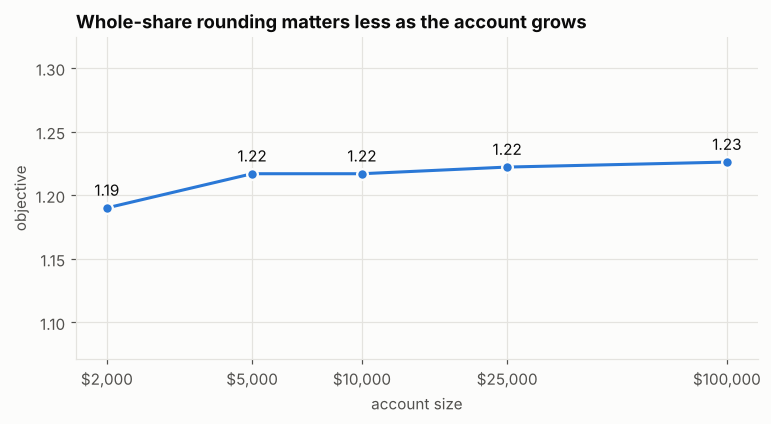

In [10]:
size_rows = []
for equity in [2000, 5000, 10_000, 25_000, 100_000]:
    o, value, p = al.allocate(cands, equity, RISK_PCT, STOP_ADR, MAX_SLOTS, GAP_BUDGET_R)
    size_rows.append({"account $": equity, "picks": " + ".join(o.index),
                      "risk R": o["risk_R"].sum(), "objective": value,
                      "coarsest share (R)": p.loc[o.index, "share_R"].max()})
sizes = pd.DataFrame(size_rows)
print(sizes.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sizes["account $"], sizes["objective"], color=ls.BLUE, marker="o", markersize=7,
        markeredgecolor=ls.SURFACE, markeredgewidth=1.5)
for xv, yv in zip(sizes["account $"], sizes["objective"]):
    ax.annotate(f"{yv:.2f}", (xv, yv), textcoords="offset points", xytext=(0, 8),
                ha="center", color=ls.TEXT)
ax.set_xscale("log"); ax.set_xticks(sizes["account $"])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}")); ax.minorticks_off()
ax.set_ylim(sizes["objective"].min() * 0.9, sizes["objective"].max() * 1.08)
ax.set_xlabel("account size"); ax.set_ylabel("objective")
ax.set_title("Whole-share rounding matters less as the account grows")
plt.show()

## Step 9 — Are the two picks really two bets?

The theme rule already blocks two stocks of one theme. This check measures
the correlation of the chosen pair directly and applies the Phase 0
formula `√((1 + ρ) / 2)`.

In [11]:
pair = sc.returns_matrix(prices["Close"], picks, 120)
rho = float(pair.corr().iloc[0, 1])
swing = np.sqrt((1 + rho) / 2)
flag = "RED: one bet" if abs(rho) >= 0.60 else "AMBER: partial overlap" if abs(rho) >= 0.30 else "GREEN: two bets"
print(f"{a} vs {b_}: correlation {rho:+.2f} over 120 days  ->  {flag}")
print(f"Two-slot swing = {swing:.0%} of putting the same risk on one name")

MRNA vs CVNA: correlation +0.25 over 120 days  ->  GREEN: two bets
Two-slot swing = 79% of putting the same risk on one name


## Step 10 — The order ticket

In [12]:
ticket = orders[["price", "stop_price", "shares", "cost", "risk_R", "gap_loss_R",
                 "score", "theme"]].copy()
ticket["risk $"] = ticket["risk_R"] * ONE_R
print(ticket.round(2).to_string())
print(f"\nTotal cost ${ticket['cost'].sum():,.2f}   total risk ${ticket['risk $'].sum():,.2f} "
      f"({ticket['risk $'].sum() / EQUITY:.2%} of equity)")
if regime["gate_open"]:
    print("Regime gate OPEN. Check each chart and the entry rules before any order.")
else:
    print("Regime gate CLOSED. Your rule allows no new breakout entries now.")
    print("Treat this ticket as an exercise, not an instruction.")
ticket.round(4).to_csv("allocation.csv")

       price  stop_price  shares    cost  risk_R  gap_loss_R  score theme  risk $
MRNA  223.37      211.98       1  223.37    0.57        1.14   84.2  solo   11.39
CVNA   72.37       70.52      10  723.70    0.93        1.85   76.7  solo   18.53

Total cost $947.07   total risk $29.92 (1.50% of equity)
Regime gate CLOSED. Your rule allows no new breakout entries now.
Treat this ticket as an exercise, not an instruction.


## What this notebook shows

The figures below are for the saved snapshot (prices to 13 Nov 2026),
a \$2,000 account, 1% risk and stops of 0.5 ADR. A refresh changes them.

1. **The picks.** MRNA (1 share, 0.57R) and CVNA (10 shares, 0.93R).
   Cost \$947, 47% of the account. Risk deployed 1.50R of the 2R allowed.
2. **The gap budget binds, not cash.** Its shadow price is 0.38 per 1R.
   Cash has \$1,217 of spare room and a shadow price of zero. Idle cash is
   again an output of the rules, as in your calculator's Section 1b.
3. **Whole shares change the answer.** With fractional shares the best
   plan is MRNA 1.00R and CVNA 0.50R (objective 1.226). One MRNA share is
   0.57R, so the real plan is different (objective 1.190).
4. **Only one rule costs anything today.** Removing the gap budget lifts
   the objective from 1.19 to 1.48. A third slot, the theme rule and the
   extension filter change nothing on this list.
5. **Tight stops and high risk cut size.** At 2.5% risk and a 0.3 ADR
   stop the rules allow 0.36R in total, against 1.93R at 1% and 1.0 ADR.
6. **Account size helps a little.** At \$100,000 the whole-share plan
   reaches the fractional optimum (1.226).
7. **The regime gate is closed.** The ticket is an exercise, not an
   instruction.

## What the allocator does not do

- **The objective is a score, not money.** Until the score is tested
  against outcomes, "optimal" means "consistent with the scanner's
  ranking and your rules".
- **Prices are the snapshot close.** Real entries are at the breakout
  price, and real stops sit at the low of the day, not at a fixed
  fraction of ADR.
- **Risk is counted, not variance.** The program limits R, cash and gap
  loss. It does not minimise `wᵀΣw`; that needs a quadratic program.
- **One day only.** No positions already open, no trading costs, no
  sequence of decisions through time.
- **Shadow prices ignore whole shares.** They describe the fractional
  version with the picks fixed.

## Exercises

1. Set `STOP_ADR = 1.0`. Which limit binds now? What happens to cash used?
2. Set `GAP_BUDGET_PCT = 0.02`. Read the new shadow price of the gap budget.
3. In Step 2, find the `link` row of the first pick. Write its inequality
   out in words.
4. Set `EQUITY = 10000`. Do the picks change? Why?
5. Add a rule: total risk at most 1.5R. Which array gets a new row, and
   what is the row? (Edit `build_problem` in `allocator.py`.)
6. Explain to a colleague how the gap budget here is like a unit capacity
   in a refinery LP, and what its shadow price means.

Next: Phase 6 joins scanner, allocator, Monte Carlo and Bayesian tracker
into one daily report.